# Projeto 2 - Task 1: Construção das séries temporais, análise exploratória e protocolo de previsão

**Objetivo do projeto:** prever o número de sessões de carregamento de VE que começam em cada uma das próximas 24 horas, ao nível da rede e de cada distrito.

## Índice

| Secção | Subsecção |
|---|---|
| **1. Preparação dos dados** | 1.1 Setup e carregamento |
| | 1.2 Auditoria da qualidade dos dados |
| | 1.3 Construção das séries horárias |
| **2. Análise exploratória** | 2.1 Evolução e tendência |
| | 2.2 Sazonalidade diária e semanal |
| | 2.3 Decomposição STL |
| | 2.4 Autocorrelação (ACF / PACF) |
| | 2.5 Diferenças entre distritos |
| | 2.6 Decisões para a formulação e avaliação |
| **3. Formulação operacional** | 3.1 Formulação do problema |
| | 3.2 Estratégia multi-step |
| | 3.3 Preditores e prevenção de leakage |
| **4. Protocolo de avaliação** | 4.1 Divisão temporal (treino / validação / teste) |
| | 4.2 Métricas (MAE, RMSE, MASE) |
| | 4.3 Baselines |
| **5. Síntese final** | — |

## 1. Preparação dos dados

### 1.1 Setup e carregamento

**Conceito: série temporal**
Uma série temporal é uma sequência de observações ordenadas no tempo (y₁, y₂, …, yₜ).
Ao contrário do Projeto 1, aqui **a ordem das linhas é informação**: não podemos alterar a ordem dos dados.

O nosso dataset **ainda não é uma série temporal**: cada linha é **uma transação**.
Vamos ter de **agregar** as transações por hora para obter a série.

In [2]:
# Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 30)

In [3]:
# O ficheiro tem caracteres chineses no cabeçalho da temperatura -> encoding latin-1
df = pd.read_csv('data/Charging_Data.csv', encoding='latin-1')

# Limpar os nomes das colunas e renomear a da temperatura (vem com caracteres estranhos)
df.columns = df.columns.str.strip()
df = df.rename(columns={df.columns[13]: 'Temperature(C)'})

# As datas vêm com um TAB no fim ("2020-12-31 23:35:55\t") -> remover antes de converter
date_cols = ['Order creation time', 'Start Time', 'End Time', 'Payment time']
for c in date_cols:
    df[c] = pd.to_datetime(df[c].astype(str).str.strip(), errors='coerce')

print(df.shape)
df.head()

(441077, 24)


,UserID,Charging Post ID,Location Information,District Name,Order creation time,Transaction power/kwh,Electricity cost/Yuan,Service charge/Yuan,Transaction Amount/Yuan,Actual Payment/Yuan,Start Time,End Time,Payment time,Temperature(C),Relative Humidity(%),Precipitation(mm),end_cause,is_full_charge,is_user_stop,is_nonsystem_fault,is_system_issue,is_EV_fault,is_other_fault,is_abnormal
0,1,1,Tourist Attraction,Nanhu,2020-12-31 23:35:55,6.24,2.60,3.74,6.34,6.34,2020-12-31 23:35:43,2020-12-31 23:48:08,2020-12-31 23:48:27,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
1,2,2,Tourist Attraction,Nanhu,2020-12-31 23:35:17,0.62,0.26,0.37,0.63,0.63,2020-12-31 23:35:19,2020-12-31 23:38:00,2020-12-31 23:38:04,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
2,3,3,Tourist Attraction,Nanhu,2020-12-31 22:01:34,28.01,11.66,16.81,28.47,28.47,2020-12-31 22:00:05,2020-12-31 22:39:38,2020-12-31 22:41:14,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
3,4,2,Tourist Attraction,Nanhu,2020-12-31 22:21:37,5.20,2.17,3.12,5.29,5.29,2020-12-31 22:21:38,2020-12-31 22:34:08,2020-12-31 22:34:12,-3.2,45,0.0,User stops charging,0,1,0,0,0,0,0
4,5,1,Tourist Attraction,Nanhu,2020-12-31 22:10:30,4.58,1.91,2.75,4.66,4.66,2020-12-31 22:10:31,2020-12-31 22:20:10,2020-12-31 22:20:16,-3.2,45,0.0,Charging ends normally,1,0,0,0,0,0,0


### 1.2 Auditoria da qualidade dos dados

O enunciado pede para **distinguir problemas de qualidade de variações legítimas da procura**:

| Tipo | Exemplo | O que fazer |
|---|---|---|
| Problema de qualidade | data inválida, fim < início, duplicados, falha no registo | corrigir / remover |
| Variação legítima | poucas sessões de madrugada, quebra num feriado | **manter**, porque é isso que queremos prever |

Vamos verificar:
1. Datas inválidas e sessões com fim antes do início
2. Linhas duplicadas
3. **Cobertura temporal**: de quando a quando há dados e se há meses "estranhos"

**Nota:** o ficheiro original **não está ordenado por data** (as primeiras linhas são de dezembro de 2020). Isto não afeta a análise, porque as transações vão ser agregadas por hora.

In [4]:
# 1) Datas inválidas e coerência temporal
print('Datas inválidas (NaT):')
print(df[date_cols].isna().sum(), '\n')

n_fim_antes = (df['End Time'] < df['Start Time']).sum()
print('Sessões com fim antes do início:', n_fim_antes)

# 2) Duplicados
print('Linhas duplicadas:', df.duplicated().sum())

# 3) Cobertura temporal
print('\nPrimeira sessão:', df['Start Time'].min())
print('Última sessão:  ', df['Start Time'].max())

Datas inválidas (NaT):
Order creation time    0
Start Time             0
End Time               0
Payment time           0
dtype: int64 

Sessões com fim antes do início: 0
Linhas duplicadas: 0

Primeira sessão: 2019-12-31 21:27:03
Última sessão:   2021-12-31 23:52:14


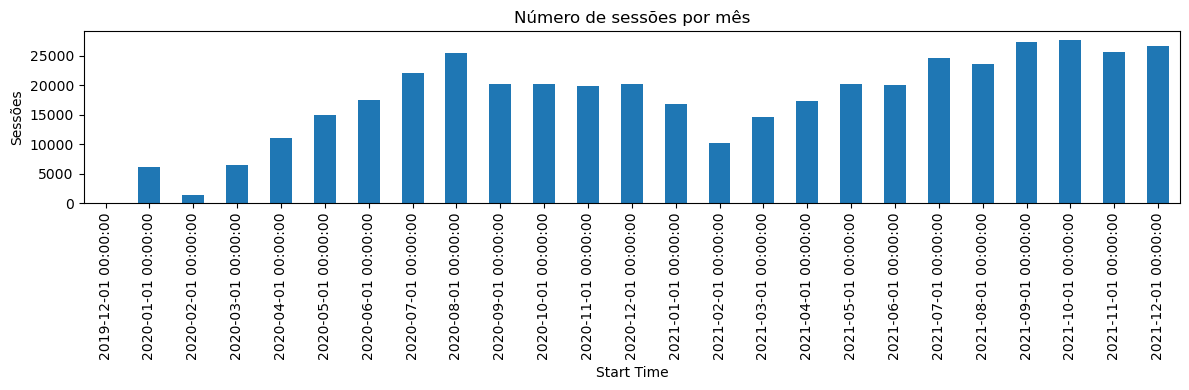

Start Time
2019-12-01       17
2020-01-01     6217
2020-02-01     1391
2020-03-01     6392
2020-04-01    11136
2020-05-01    15033
2020-06-01    17513
2020-07-01    22032
2020-08-01    25562
2020-09-01    20231
2020-10-01    20252
2020-11-01    19925
2020-12-01    20187
2021-01-01    16915
2021-02-01    10283
2021-03-01    14599
2021-04-01    17307
2021-05-01    20209
2021-06-01    20026
2021-07-01    24703
2021-08-01    23692
2021-09-01    27374
2021-10-01    27794
2021-11-01    25669
2021-12-01    26618
Freq: MS, dtype: int64

In [5]:
# Nº de sessões por mês -> ver se há meses incompletos ou anómalos
sessoes_mes = df.set_index('Start Time').resample('MS').size()

sessoes_mes.plot(kind='bar', figsize=(12, 4), color='tab:blue')
plt.title('Número de sessões por mês')
plt.ylabel('Sessões')
plt.tight_layout()
plt.show()

sessoes_mes

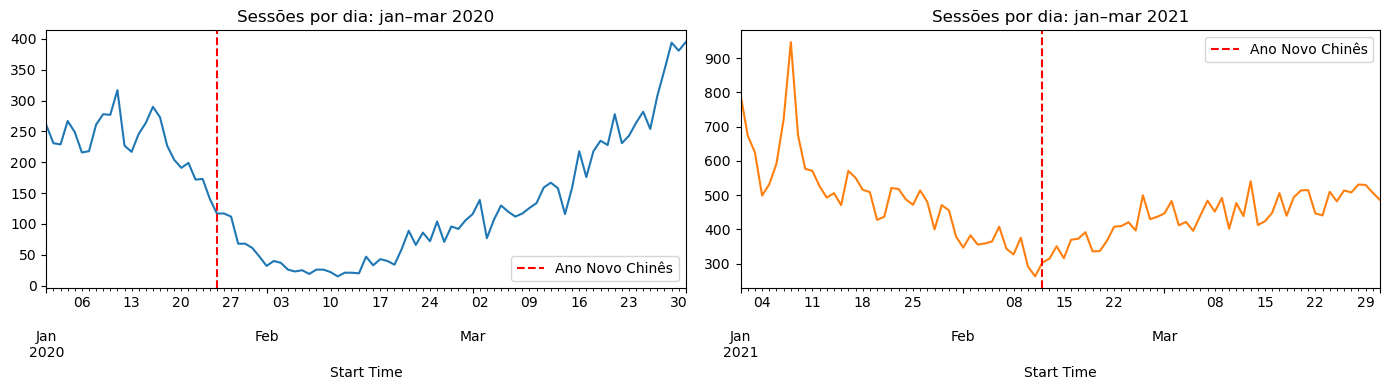

Start Time
2020-01    200.5
2020-02     48.0
2020-03    206.2
2020-04    371.2
2020-05    484.9
2020-06    583.8
2020-07    710.7
2020-08    824.6
2020-09    674.4
2020-10    653.3
2020-11    664.2
2020-12    651.2
2021-01    545.6
2021-02    367.2
2021-03    470.9
2021-04    576.9
2021-05    651.9
2021-06    667.5
2021-07    796.9
2021-08    764.3
2021-09    912.5
2021-10    896.6
2021-11    855.6
2021-12    858.6
dtype: float64

In [6]:
# Validar H2: sessões por DIA à volta do Ano Novo Chinês
# Ano Novo Chinês: 25/01/2020 e 12/02/2021
sessoes_dia = df.set_index('Start Time').resample('D').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)

sessoes_dia['2020-01-01':'2020-03-31'].plot(ax=axes[0], color='tab:blue')
axes[0].axvline(pd.Timestamp('2020-01-25'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[0].set_title('Sessões por dia: jan–mar 2020')
axes[0].legend()

sessoes_dia['2021-01-01':'2021-03-31'].plot(ax=axes[1], color='tab:orange')
axes[1].axvline(pd.Timestamp('2021-02-12'), color='red', linestyle='--', label='Ano Novo Chinês')
axes[1].set_title('Sessões por dia: jan–mar 2021')
axes[1].legend()

plt.tight_layout()
plt.show()

# Média diária por mês (corrige o efeito de fevereiro ter menos dias)
media_diaria = sessoes_dia['2020-01-01':].resample('MS').mean().round(1)
media_diaria.index = media_diaria.index.strftime('%Y-%m')
media_diaria

**Hipóteses e validação:**

- **H1 — Dezembro de 2019 é um mês incompleto: Confirmada.**
  A primeira sessão ocorre a 31/12/2019 às 21:27 (apenas 17 sessões). É um problema de **cobertura** e não procura real.
  **Decisão:** a série começa a **01/01/2020**.

- **H2 — As quebras de fevereiro são variações legítimas: Confirmada, com nuances.**
  - **2020:** quebra longa (de meados de janeiro ao fim de março), com mínimo de cerca de 20 sessões/dia. Compatível com o Ano Novo Chinês (25/01) e as restrições da COVID-19. É procura real, mas **atípica**.
  - **2021:** quebra moderada e concentrada à volta do Ano Novo Chinês (12/02). A média diária de fevereiro (367) é inferior à de janeiro (546), o que confirma que o efeito não se deve apenas a fevereiro ter menos dias.

  **Decisão:** não remover estes períodos (não são erros), mas **assinalar jan–mar 2020 como período atípico**, a considerar na escolha do período de treino (secção 2.6).

**Outras observações:**
- A procura tem uma **tendência crescente forte**: a média diária passa de ~200 (jan/2020) para ~860 (dez/2021).
- Pico isolado a **08/01/2021** (~950 sessões), a analisar na secção 2.
- Não foram encontradas datas inválidas, sessões com fim antes do início nem linhas duplicadas.

### 1.3 Construção das séries horárias

**Conceito: frequência e granularidade**
- **Frequência:** de quanto em quanto tempo temos um valor → **horária**
- **Granularidade:** a que nível agregamos → **rede** (total) e **distrito** (3 séries)

**Como construir:**
1. Arredondar o `Start Time` para baixo, à hora (`floor('h')`), porque o alvo são sessões que **começam** em cada hora
2. Contar as sessões por hora
3. Criar um índice com **todas** as horas do período. As horas sem nenhuma sessão não aparecem na contagem, por isso temos de as acrescentar com valor **0**

**Atenção:** uma hora sem sessões pode ser **procura zero real** (madrugada) ou **falha de registo**. Vamos analisar isso a seguir.

**Período:** de 01/01/2020 00:00 a 31/12/2021 23:00 (decisão da H1).

In [7]:
df['hora'] = df['Start Time'].dt.floor('h')

# Índice completo: todas as horas entre o início e o fim do período
idx = pd.date_range('2020-01-01 00:00', '2021-12-31 23:00', freq='h')

# Série da REDE
rede = df.groupby('hora').size().reindex(idx, fill_value=0)
rede.name = 'Rede'

# Séries por DISTRITO (uma coluna por distrito)
distritos = (df.groupby(['hora', 'District Name']).size()
               .unstack(fill_value=0)
               .reindex(idx, fill_value=0))

series = pd.concat([rede, distritos], axis=1)
series.index.name = 'hora'

print('Nº de horas:', len(series))
print('Confirmação (soma dos distritos = rede):',
      (series[distritos.columns].sum(axis=1) == series['Rede']).all())
series.head()

Nº de horas: 17544
Confirmação (soma dos distritos = rede): True


,Rede,Nanhu,Tongxiang,Xiuzhou
hora,,,,
2020-01-01 00:00:00,16,0,11,5
2020-01-01 01:00:00,3,2,1,0
2020-01-01 02:00:00,1,0,1,0
2020-01-01 03:00:00,5,0,4,1
2020-01-01 04:00:00,4,0,2,2


In [8]:
# Total de sessões na série (as 17 sessões de dez/2019 ficaram de fora)
print('Total de sessões nas séries:', series['Rede'].sum(), '\n')

# Horas com ZERO sessões em cada série
zeros = (series == 0).sum()
print('Horas com 0 sessões:')
pd.DataFrame({'n_horas': zeros, '% do total': (zeros / len(series) * 100).round(2)})

Total de sessões nas séries: 441060 

Horas com 0 sessões:


,n_horas,% do total
Rede,480,2.74
Nanhu,3582,20.42
Tongxiang,1012,5.77
Xiuzhou,1741,9.92


In [9]:
# Sequências de zeros consecutivos na REDE
# Zeros isolados de madrugada -> normal. Muitas horas seguidas a zero -> suspeito.
z = series['Rede'] == 0
grupo = (z != z.shift()).cumsum()

blocos = (series.loc[z, 'Rede']
          .groupby(grupo[z])
          .agg(inicio=lambda s: s.index.min(), n_horas='size')
          .sort_values('n_horas', ascending=False))

# Em que meses e a que horas do dia aparecem os zeros da rede?
zeros_rede = series.index[z]
print('Zeros da rede por mês:')
print(zeros_rede.to_period('M').value_counts().sort_index().to_string(), '\n')
print('Zeros da rede por hora do dia:')
print(zeros_rede.hour.value_counts().sort_index().to_dict(), '\n')

print('Os 10 blocos de zeros mais longos:')
blocos.head(10)

Zeros da rede por mês:
hora
2020-01     60
2020-02    277
2020-03     89
2020-04     11
2020-05      3
2020-10      1
2020-11      1
2020-12      3
2021-01      5
2021-02     13
2021-03      7
2021-04      2
2021-05      1
2021-06      4
2021-07      1
2021-08      1
2021-12      1
Freq: M 

Zeros da rede por hora do dia:
{0: 22, 1: 34, 2: 47, 3: 55, 4: 65, 5: 66, 6: 52, 7: 34, 8: 15, 9: 15, 10: 9, 11: 6, 12: 5, 13: 3, 14: 3, 15: 2, 16: 3, 17: 4, 18: 8, 19: 7, 20: 6, 21: 3, 22: 6, 23: 10} 

Os 10 blocos de zeros mais longos:


,inicio,n_horas
Rede,,
192,2020-02-13 23:00:00,12
198,2020-02-15 00:00:00,10
164,2020-02-09 22:00:00,10
172,2020-02-11 01:00:00,10
158,2020-02-09 01:00:00,9
102,2020-02-04 02:00:00,9
206,2020-02-16 23:00:00,8
230,2020-02-20 00:00:00,8
202,2020-02-16 00:00:00,8


In [10]:
# Zeros da rede FORA do período atípico (a partir de abril de 2020)
zeros_normais = zeros_rede[zeros_rede >= '2020-04-01']

print('Nº de zeros a partir de abr/2020:', len(zeros_normais))
print('Por hora do dia:', zeros_normais.hour.value_counts().sort_index().to_dict())

Nº de zeros a partir de abr/2020: 54
Por hora do dia: {2: 7, 3: 6, 4: 12, 5: 20, 6: 7, 7: 2}


**Hipóteses e validação:**

- **H3 - Séries com menor volume têm mais horas a zero: Confirmada.**
  Rede: 2,74% | Tongxiang: 5,77% | Xiuzhou: 9,92% | Nanhu: 20,42%.
  A ordem coincide com o volume de sessões de cada distrito. Em **Nanhu**, 1 em cada 5 horas não tem sessões, o que torna esta série mais **irregular** e, à partida, mais difícil de prever.

- **H4 - Os zeros da rede são procura real e não falhas de registo: Confirmada.**
  - 426 dos 480 zeros (~89%) ocorrem em **jan–mar 2020** (período atípico, ver H2);
  - fora desse período existem apenas 54 zeros, **todos entre as 2h e as 7h** (madrugada);
  - o bloco mais longo de zeros tem **12 horas** (fev/2020); **não existe nenhum dia inteiro sem sessões**.

**Decisão:** os zeros são mantidos como **procura zero real** (sem imputação). Não foram detetados intervalos em falta na série.

## 2. Análise exploratória

### 2.1 Evolução e tendência

**Conceito: componentes de uma série temporal**

| Componente | O que é |
|---|---|
| **Nível** | valor médio da série |
| **Tendência** | aumento ou diminuição de longo prazo |
| **Sazonalidade** | padrão que se repete em intervalos fixos (ex.: todos os dias, todas as semanas) |
| **Ciclo** | flutuações longas sem duração fixa |
| **Ruído** | variação irregular e imprevisível |

Com dados **horários**, a série é muito "ruidosa" e é difícil ver a tendência.
Por isso, nesta secção agregamos por **dia** e usamos uma **média móvel de 30 dias**, que suaviza as oscilações de curto prazo e deixa ver a tendência.

**Conceito: média móvel**
A média móvel de 30 dias substitui cada valor pela média dos 30 dias à sua volta. Os padrões curtos (diário, semanal) desaparecem e fica a evolução de longo prazo.

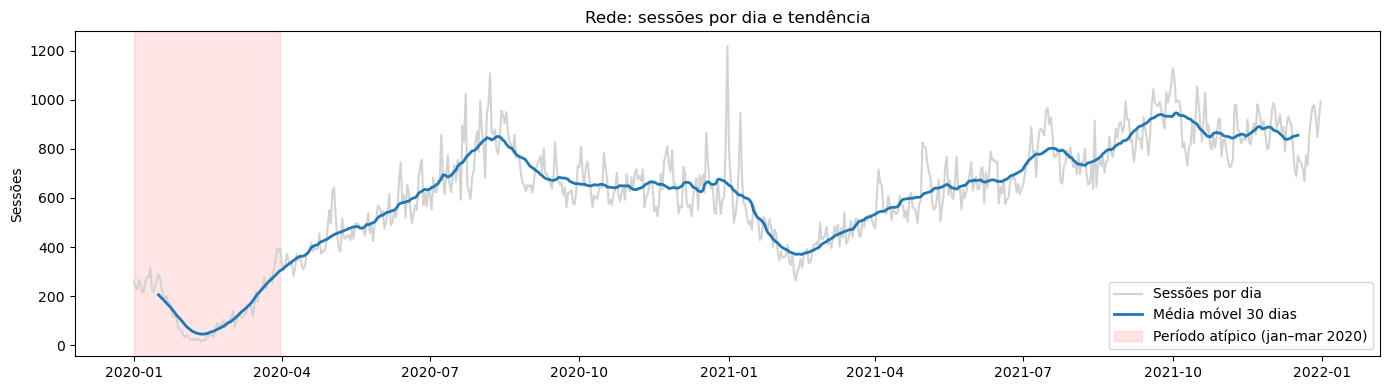

In [11]:
# Série diária (soma das 24 horas de cada dia)
diario = series.resample('D').sum()

# Média móvel de 30 dias (centrada)
mm30 = diario['Rede'].rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(diario.index, diario['Rede'], color='lightgray', label='Sessões por dia')
ax.plot(mm30.index, mm30, color='tab:blue', linewidth=2, label='Média móvel 30 dias')
ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2020-03-31'),
           color='red', alpha=0.1, label='Período atípico (jan–mar 2020)')
ax.set_title('Rede: sessões por dia e tendência')
ax.set_ylabel('Sessões')
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# Média diária por trimestre -> resumo numérico da tendência
media_trimestral = diario['Rede'].resample('QS').mean().round(1)
media_trimestral.index = media_trimestral.index.to_period('Q').astype(str)
print('Média de sessões por dia, por trimestre:')
print(media_trimestral.to_string(), '\n')

# Os 5 dias com mais sessões (possíveis picos atípicos)
print('Os 5 dias com mais sessões:')
print(diario['Rede'].nlargest(5).to_string())

Média de sessões por dia, por trimestre:
hora
2020Q1    153.8
2020Q2    480.0
2020Q3    737.2
2020Q4    656.1
2021Q1    464.4
2021Q2    632.3
2021Q3    823.6
2021Q4    870.4 

Os 5 dias com mais sessões:
hora
2020-12-31    1219
2021-10-01    1128
2020-08-07    1108
2021-10-02    1091
2021-09-30    1055


**Hipóteses e validação:**

- **H5 - A procura média aumenta de trimestre para trimestre: Rejeitada tal como formulada, mas existe tendência crescente.**
  A média diária desce do 3.º para o 4.º trimestre de 2020 (737 → 656) e de novo no 1.º trimestre de 2021 (464).
  No entanto, comparando **trimestres homólogos**, a procura cresce sempre:

  | Trimestre | 2020 | 2021 |
  |---|---|---|
  | T1 | 153,8 | 464,4 |
  | T2 | 480,0 | 632,3 |
  | T3 | 737,2 | 823,6 |
  | T4 | 656,1 | 870,4 |

  **Conclusão:** existe uma **tendência crescente de longo prazo**, sobreposta a variações ao longo do ano. Por isso a série **não é estacionária** (a média não é constante).

- **H6 - Existe um padrão ao longo do ano: Sugerida, mas não confirmada.**
  Nos dois anos, a procura sobe até ao verão/outono e cai no inverno (jan–fev, Ano Novo Chinês). Com apenas 2 ciclos, e com 2020 afetado pela COVID-19, não é possível confirmar uma sazonalidade anual.

- **H7 - Os dias com mais sessões são picos associados a datas especiais: Confirmada.**
  - 31/12/2020 (1219 sessões): véspera de Ano Novo;
  - 30/09 a 02/10/2021: início do feriado do Dia Nacional da China (Golden Week);
  - 07/08/2020: sem explicação evidente no calendário.

  São procura real e não erros. **Implicação:** variáveis de calendário (feriados, vésperas de feriado) são candidatas a preditores (secção 3.3).

### 2.2 Sazonalidade diária e semanal

**Conceito: sazonalidade e período sazonal *m***
A sazonalidade é um padrão que se repete em intervalos fixos. O **período sazonal *m*** é o número de observações de um ciclo completo:

| Padrão | Ciclo | *m* (em horas) |
|---|---|---|
| Diário | 1 dia | **24** |
| Semanal | 1 semana | **168** (7 × 24) |

No exemplo da aula (*Air Passengers*, dados mensais), *m* = 12. No nosso caso, com dados **horários**, podem existir **dois padrões ao mesmo tempo** (diário e semanal).

O *m* é uma decisão importante, porque vai ser usado:
- no **seasonal naïve** (prever "o mesmo valor de há *m* horas");
- no **MASE** (métrica de avaliação);
- na **decomposição STL** (secção 2.3).

**Como vamos analisar: perfis médios**
- **Perfil diário:** média de sessões para cada hora do dia (0h a 23h);
- **Perfil semanal:** média de sessões para cada dia da semana;
- **Perfil hora × dia da semana:** o perfil diário separado por dia da semana, para ver se a "forma" do dia muda (ex.: fim de semana vs. dias úteis).

**Decisão:** usamos os dados **a partir de 01/04/2020**, para o período atípico (jan–mar 2020) não distorcer as médias.

**Medida simples da intensidade de cada padrão:**
amplitude relativa = (máximo − mínimo) / média do perfil.
Quanto maior, mais forte é o padrão.

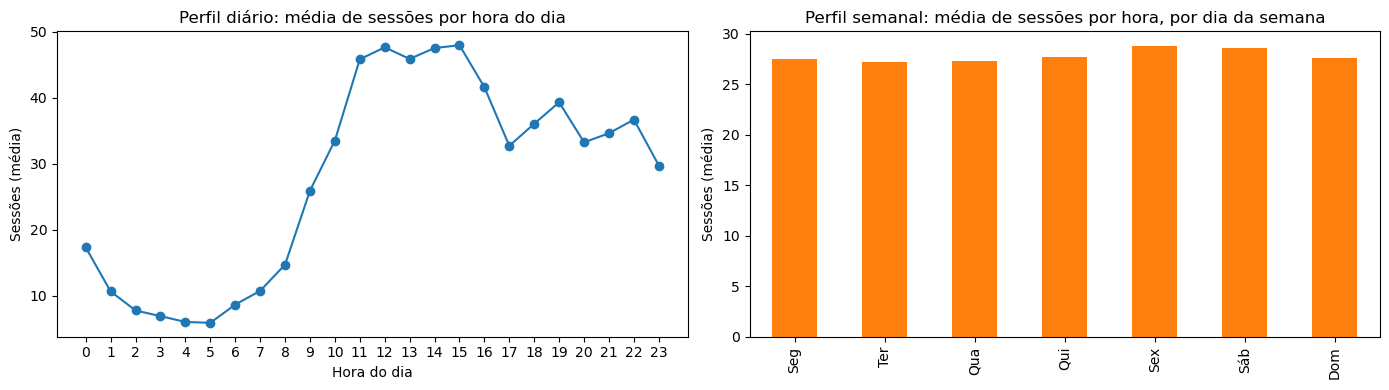

Amplitude relativa do padrão diário:  1.51
Amplitude relativa do padrão semanal: 0.06


In [13]:
# Dados a partir de abril de 2020 (sem o período atípico)
s = series.loc['2020-04-01':, ['Rede']].copy()
s['hora_dia'] = s.index.hour
s['dia_semana'] = s.index.dayofweek          # 0 = segunda, 6 = domingo
nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

# Perfil diário e perfil semanal (média de sessões por hora)
perfil_hora = s.groupby('hora_dia')['Rede'].mean()
perfil_dia = s.groupby('dia_semana')['Rede'].mean()
perfil_dia.index = nomes_dias

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

perfil_hora.plot(ax=axes[0], marker='o', color='tab:blue')
axes[0].set_title('Perfil diário: média de sessões por hora do dia')
axes[0].set_xlabel('Hora do dia')
axes[0].set_ylabel('Sessões (média)')
axes[0].set_xticks(range(0, 24))

perfil_dia.plot(kind='bar', ax=axes[1], color='tab:orange')
axes[1].set_title('Perfil semanal: média de sessões por hora, por dia da semana')
axes[1].set_ylabel('Sessões (média)')

plt.tight_layout()
plt.show()

# Amplitude relativa de cada padrão
def amplitude(perfil):
    return (perfil.max() - perfil.min()) / perfil.mean()

print(f'Amplitude relativa do padrão diário:  {amplitude(perfil_hora):.2f}')
print(f'Amplitude relativa do padrão semanal: {amplitude(perfil_dia):.2f}')

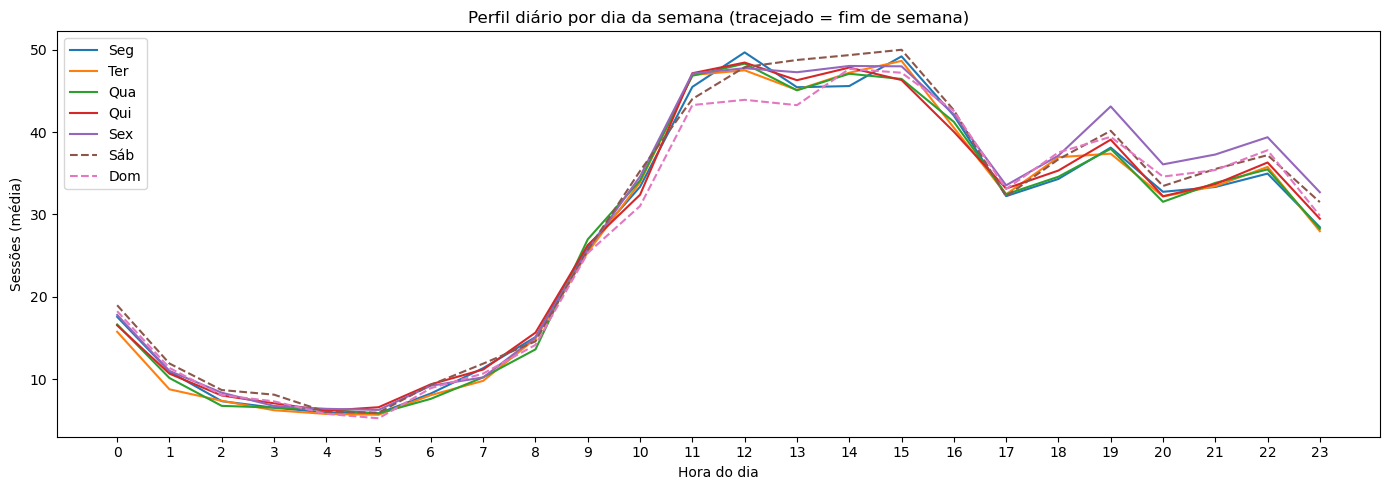

In [14]:
# Perfil diário separado por dia da semana -> a "forma" do dia muda ao fim de semana?
tabela = s.pivot_table(index='hora_dia', columns='dia_semana', values='Rede', aggfunc='mean')
tabela.columns = nomes_dias

fig, ax = plt.subplots(figsize=(14, 5))
for dia in nomes_dias:
    estilo = '--' if dia in ['Sáb', 'Dom'] else '-'
    ax.plot(tabela.index, tabela[dia], linestyle=estilo, label=dia)

ax.set_title('Perfil diário por dia da semana (tracejado = fim de semana)')
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Sessões (média)')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

**Hipóteses e validação:**

- **H8 - Existe uma sazonalidade diária forte (*m* = 24): Confirmada.**
  Amplitude relativa de **1,51**. O perfil diário apresenta:
  - mínimo entre as 4h e as 5h (~6 sessões/hora);
  - subida rápida entre as 8h e as 11h;
  - patamar máximo entre as 11h e as 15h (~46–48 sessões/hora, cerca de 8 vezes o mínimo);
  - quebra às 17h (~33) e um segundo pico às 19h (~39);
  - descida a partir das 23h.

- **H9 - O fim de semana tem um nível ou uma forma diferente dos dias úteis: Rejeitada.**
  Amplitude relativa do padrão semanal de apenas **0,06** (cerca de 25 vezes inferior à diária).
  Os perfis diários dos 7 dias estão praticamente sobrepostos. Existem apenas diferenças pequenas e localizadas:
  - domingo com menos procura entre as 11h e as 13h;
  - sábado com ligeiramente mais procura à tarde;
  - sexta-feira com mais procura à noite (19h–23h).

**Conclusão:** a sazonalidade **diária (*m* = 24) é dominante**. A sazonalidade semanal (*m* = 168) é fraca, mas não nula.

**Implicação para a previsão:** não se deve descartar *m* = 168 apenas com base nos perfis médios. A escolha final do *m* vai ser confirmada com a ACF (secção 2.4) e comparando os baselines seasonal naïve com *m* = 24 e *m* = 168 (secção 4.3).

### 2.3 Decomposição STL

**Conceito: decomposição**
A decomposição separa a série nas suas componentes:

- **Aditiva:** yₜ = Tendência + Sazonalidade + Resíduo → a amplitude sazonal é **constante**
- **Multiplicativa:** yₜ = Tendência × Sazonalidade × Resíduo → a amplitude sazonal **cresce com o nível** da série

**Conceito: STL**
O STL (*Seasonal and Trend decomposition using Loess*) é robusto a outliers e aceita qualquer período. É uma decomposição **aditiva**. Para uma série multiplicativa, aplica-se primeiro o **logaritmo**, que transforma a multiplicação em soma:

log(T × S × R) = log(T) + log(S) + log(R)

**Adaptações aos nossos dados:**
1. **log(1 + y) em vez de log(y):** a série tem horas com 0 sessões e log(0) não existe. A função `np.log1p` calcula log(1 + y) e resolve o problema.
2. **MSTL em vez de STL:** o STL só aceita **um** período sazonal. O **MSTL** (*Multiple STL*) é a mesma técnica aplicada a **vários períodos ao mesmo tempo**. Assim separamos a sazonalidade de 24h da de 168h.

**Conceito: força de uma componente (*seasonal strength*, notebook da aula)**

força = max(0, 1 − Var(resíduo) / Var(componente + resíduo))

Mede quanto da variação é explicada pela componente: **perto de 1 = forte**, **perto de 0 = fraca**.

**Dados usados:** a partir de 01/04/2020, sem o período atípico (como na secção 2.2).

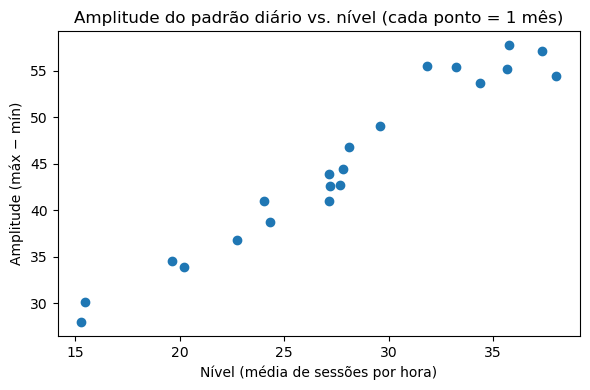

Correlação entre nível e amplitude: 0.97

Amplitude relativa (amplitude / nível) por mês:
count    21.00
mean      1.64
std       0.12
min       1.43
25%       1.56
50%       1.62
75%       1.68
max       1.95
dtype: float64


In [15]:
from statsmodels.tsa.seasonal import MSTL

# Teste: aditiva ou multiplicativa?
# Para cada mês, calculamos o nível (média) e a amplitude do perfil diário.
# Se a amplitude cresce com o nível -> multiplicativa.
y = series.loc['2020-04-01':, 'Rede']

tmp = y.to_frame('sessoes')
tmp['mes'] = tmp.index.to_period('M')
tmp['hora_dia'] = tmp.index.hour

perfis_mes = tmp.groupby(['mes', 'hora_dia'])['sessoes'].mean().unstack()
nivel = perfis_mes.mean(axis=1)
amplitude_abs = perfis_mes.max(axis=1) - perfis_mes.min(axis=1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(nivel, amplitude_abs, color='tab:blue')
ax.set_title('Amplitude do padrão diário vs. nível (cada ponto = 1 mês)')
ax.set_xlabel('Nível (média de sessões por hora)')
ax.set_ylabel('Amplitude (máx − mín)')
plt.tight_layout()
plt.show()

print(f'Correlação entre nível e amplitude: {np.corrcoef(nivel, amplitude_abs)[0, 1]:.2f}')
print('\nAmplitude relativa (amplitude / nível) por mês:')
print((amplitude_abs / nivel).describe().round(2))

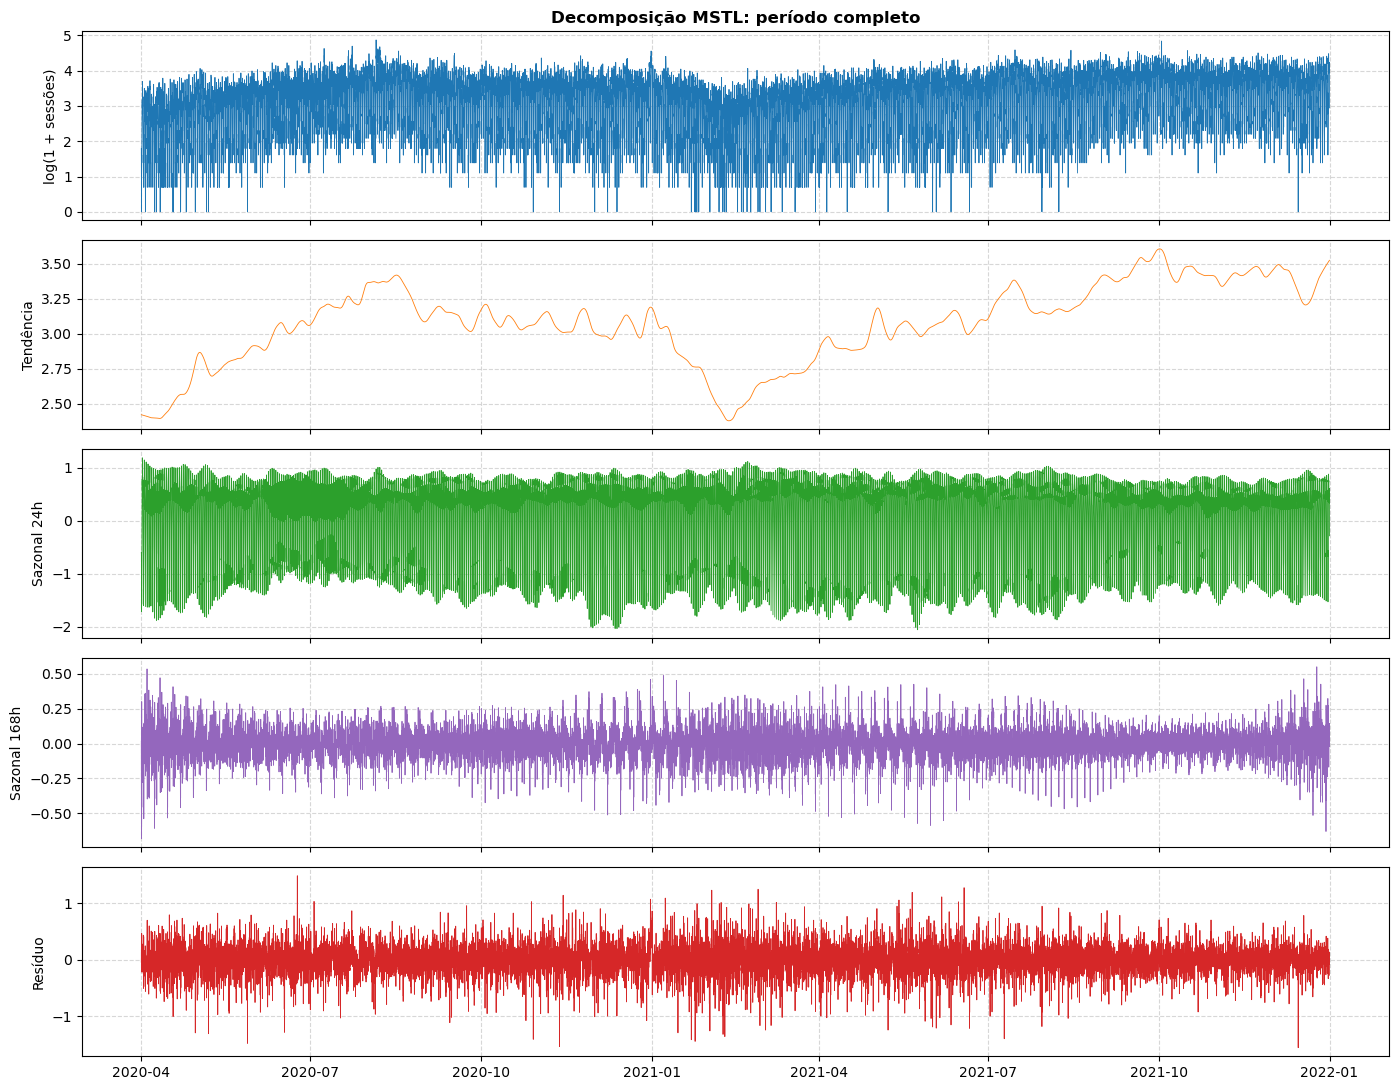

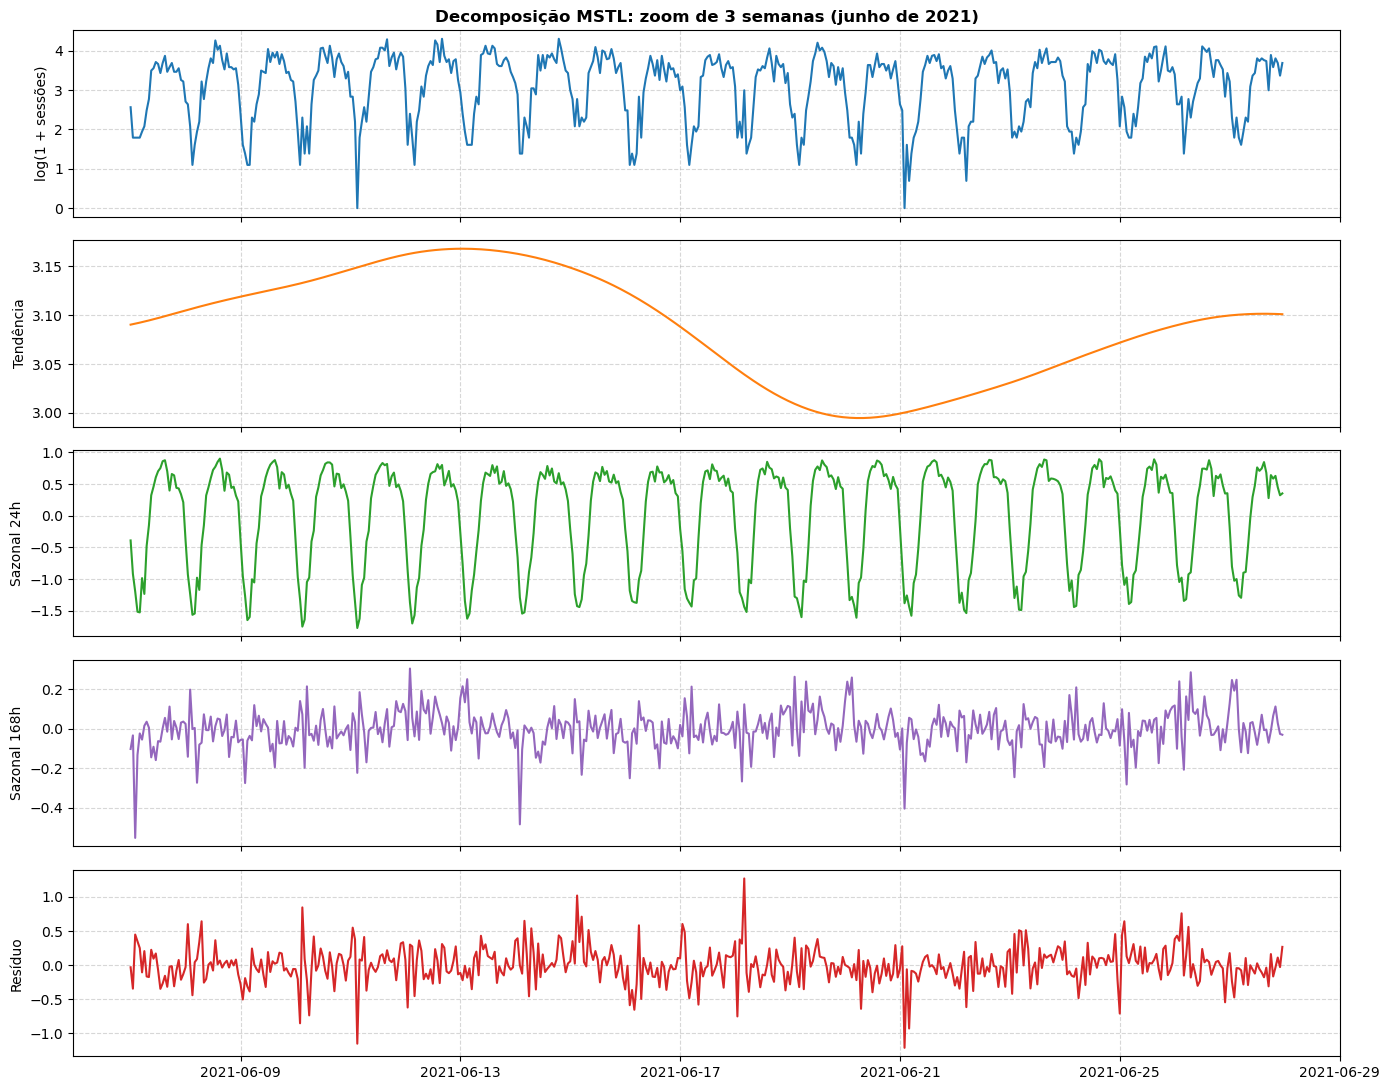

In [16]:
# Decomposição MSTL com log(1 + y) e dois períodos sazonais (24h e 168h)
y_log = np.log1p(y)
decomp = MSTL(y_log, periods=(24, 168)).fit()

componentes = [(decomp.observed,                'log(1 + sessões)', 'tab:blue'),
               (decomp.trend,                   'Tendência',        'tab:orange'),
               (decomp.seasonal['seasonal_24'], 'Sazonal 24h',      'tab:green'),
               (decomp.seasonal['seasonal_168'],'Sazonal 168h',     'tab:purple'),
               (decomp.resid,                   'Resíduo',          'tab:red')]

# Gráfico 1: período completo
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, (comp, nome, cor) in zip(axes, componentes):
    ax.plot(comp, color=cor, linewidth=0.6)
    ax.set_ylabel(nome)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_title('Decomposição MSTL: período completo', fontweight='bold')
plt.tight_layout()
plt.show()

# Gráfico 2: zoom em 3 semanas (com 15 mil horas não se veem os padrões)
janela = slice('2021-06-07', '2021-06-27')
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, (comp, nome, cor) in zip(axes, componentes):
    ax.plot(comp.loc[janela], color=cor)
    ax.set_ylabel(nome)
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_title('Decomposição MSTL: zoom de 3 semanas (junho de 2021)', fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# Força de cada componente (mesma fórmula do notebook da aula)
residuo = decomp.resid

def forca(componente):
    return max(0, 1 - residuo.var() / (componente + residuo).var())

print(f'Força da tendência:          {forca(decomp.trend):.3f}')
print(f'Força da sazonalidade 24h:   {forca(decomp.seasonal["seasonal_24"]):.3f}')
print(f'Força da sazonalidade 168h:  {forca(decomp.seasonal["seasonal_168"]):.3f}')

Força da tendência:          0.560
Força da sazonalidade 24h:   0.898
Força da sazonalidade 168h:  0.186


**Hipóteses e validação:**

- **H10 - A série é multiplicativa: Confirmada.**
  A amplitude do padrão diário cresce com o nível da série (correlação de **0,97** entre nível e amplitude mensais). A amplitude relativa mantém-se aproximadamente constante (média de **1,64**, desvio padrão de 0,12), o que corresponde à definição de sazonalidade multiplicativa.
  Após a transformação log(1 + y), a amplitude da componente sazonal de 24h fica estável ao longo do tempo, o que confirma que a transformação é adequada.

- **H11 - A sazonalidade de 24h é forte e a de 168h é fraca: Confirmada.**

  | Componente | Força |
  |---|---|
  | Sazonalidade 24h | 0,898 |
  | Tendência | 0,560 |
  | Sazonalidade 168h | 0,186 |

  - A componente de **24h** é muito regular e repete a mesma forma todos os dias.
  - A componente de **168h** não mostra uma forma clara que se repita semanalmente e tem uma escala semelhante à do resíduo.
  - A **tendência** reproduz a evolução observada na secção 2.1.

**Conclusões:**
- A decomposição confirma, com uma técnica diferente, os resultados dos perfis médios (secção 2.2): o **padrão diário é dominante** e o semanal é fraco, mas não nulo.
- A série deve ser tratada como **multiplicativa**. A transformação log(1 + y) é uma opção a considerar nos modelos das próximas tarefas.
- A escolha do *m* (24 ou 168) vai ser confirmada com a ACF (secção 2.4) e com a comparação dos baselines (secção 4.3).

### 2.4 Autocorrelação (ACF / PACF)

**Conceito: lag e autocorrelação**
Um **lag** é a distância temporal entre duas observações. Com dados horários:
- lag 1 → compara yₜ com a hora anterior (yₜ₋₁)
- lag 24 → compara yₜ com a mesma hora do dia anterior (yₜ₋₂₄)
- lag 168 → compara yₜ com a mesma hora da semana anterior (yₜ₋₁₆₈)

A **ACF** (função de autocorrelação) mede a correlação da série consigo própria em cada lag.

**Como ler a ACF:**
- **Picos em múltiplos de *m*** → sazonalidade com período *m* (no exemplo da aula, pico no lag 12)
- **Decaimento lento** → possível tendência / não estacionariedade
- Valores dentro da **banda azul** → não significativos

**Conceito: PACF**:
A ACF inclui relações **diretas e indiretas** (yₜ ← yₜ₋₁ ← yₜ₋₂). A **PACF** mede apenas a relação **direta** entre yₜ e yₜ₋ₖ, depois de remover o efeito dos lags intermédios. Ajuda a perceber **que lags passados são realmente úteis** para prever.

**Como testar a sazonalidade semanal:**
Se existir um padrão semanal, o lag 168 deve ter uma autocorrelação **maior** que os lags vizinhos 144 e 192 (que correspondem a "6 dias" e "8 dias" atrás).

**Conceito: diferenciação sazonal**
Δ₂₄yₜ = yₜ − yₜ₋₂₄ remove o padrão diário. Se depois disso ainda houver um pico no lag 168, existe informação semanal **para além** do padrão diário.

**Dados usados:** log(1 + y) a partir de 01/04/2020 (decisão da secção 2.3).

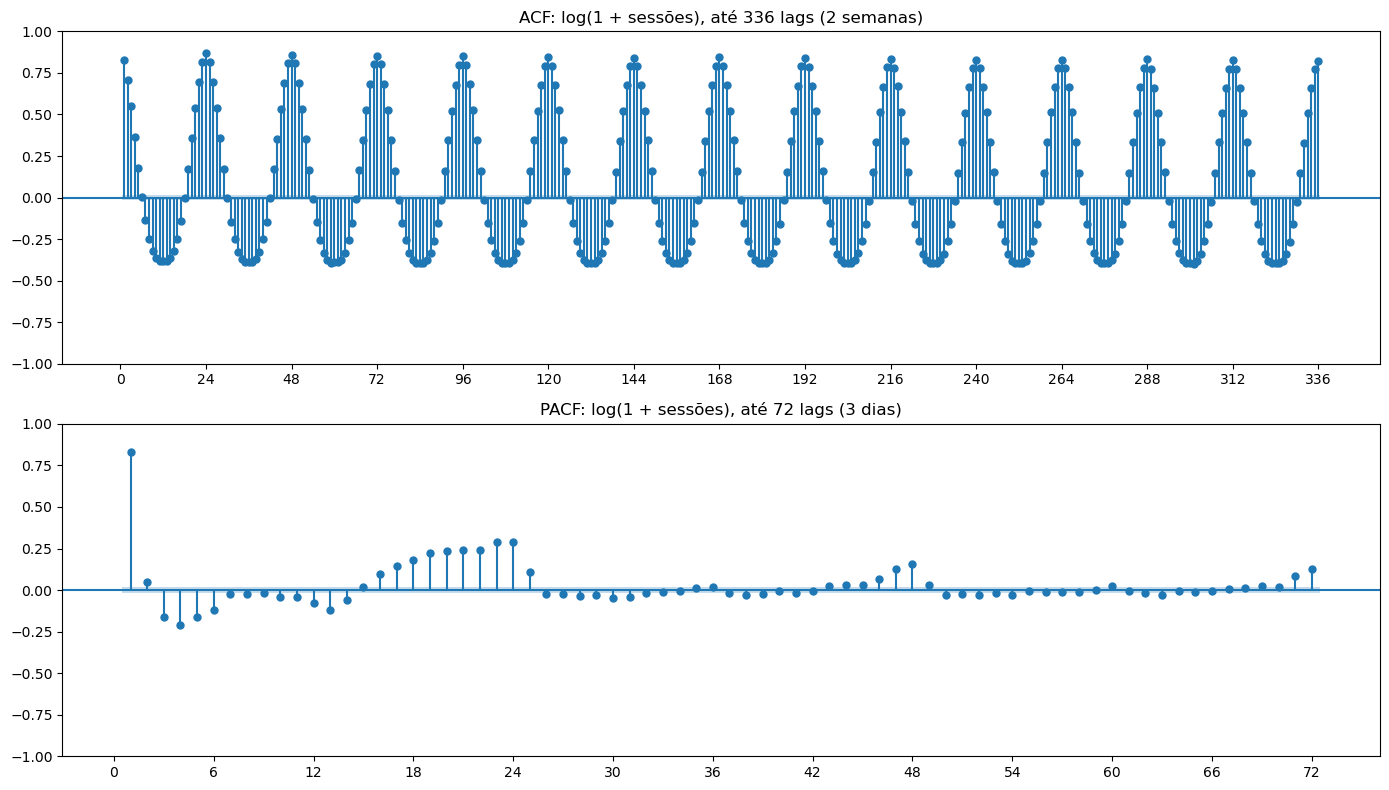

In [18]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, adfuller

# y_log já foi criado na secção 2.3: log(1 + sessões) a partir de abr/2020
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_log, lags=336, zero=False, bartlett_confint=False, ax=axes[0])
axes[0].set_title('ACF: log(1 + sessões), até 336 lags (2 semanas)')
axes[0].set_xticks(range(0, 337, 24))

plot_pacf(y_log, lags=72, zero=False, method='ywm', ax=axes[1])
axes[1].set_title('PACF: log(1 + sessões), até 72 lags (3 dias)')
axes[1].set_xticks(range(0, 73, 6))

plt.tight_layout()
plt.show()

In [19]:
# Valores da ACF em lags-chave
def tabela_acf(serie, lags):
    valores = acf(serie, nlags=max(lags))
    return pd.Series({lag: round(valores[lag], 3) for lag in lags}, name='ACF')

lags_chave = [1, 2, 12, 24, 48, 144, 167, 168, 169, 192, 336]
print('ACF da série log(1 + y):')
print(tabela_acf(y_log, lags_chave).to_string())

ACF da série log(1 + y):
1      0.830
2      0.705
12    -0.384
24     0.868
48     0.858
144    0.842
167    0.792
168    0.844
169    0.793
192    0.838
336    0.825


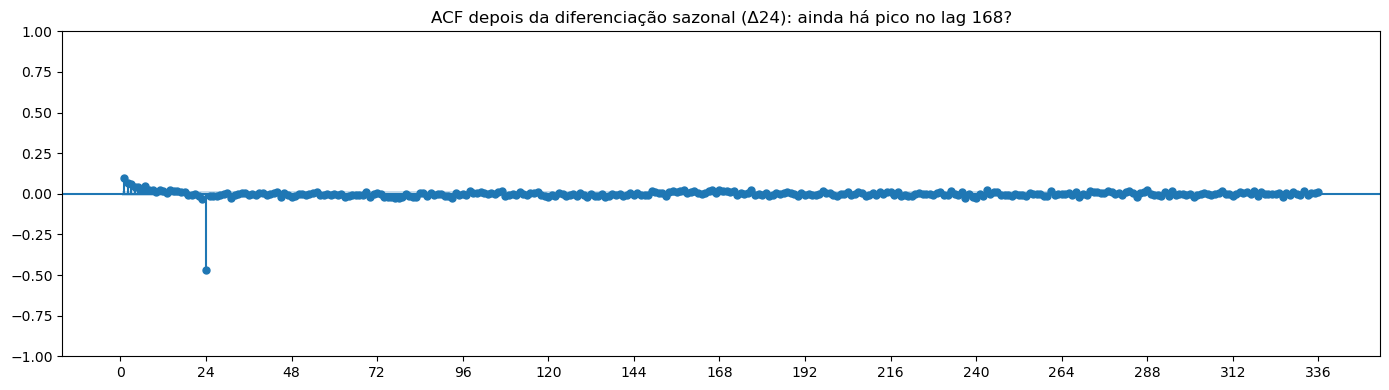

ACF da série diferenciada (Δ24):
1      0.097
24    -0.470
48    -0.020
144   -0.008
168    0.026
192   -0.007
336    0.012


In [20]:
# ACF depois de remover o padrão diário (diferenciação sazonal com lag 24)
y_dif24 = y_log.diff(24).dropna()

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(y_dif24, lags=336, zero=False, bartlett_confint=False, ax=ax)
ax.set_title('ACF depois da diferenciação sazonal (Δ24): ainda há pico no lag 168?')
ax.set_xticks(range(0, 337, 24))
plt.tight_layout()
plt.show()

print('ACF da série diferenciada (Δ24):')
print(tabela_acf(y_dif24, [1, 24, 48, 144, 168, 192, 336]).to_string())

In [21]:
# Teste de estacionariedade ADF (função do notebook da aula)
def test_stationarity(serie):
    print('Results of Augmented Dickey-Fuller Test:')
    dftest = adfuller(serie.values, autolag='AIC')

    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '# Lags', '# Observations'])
    for key, value in dftest[4].items():
        dfoutput['Critical Value (%s)' % key] = value
    print(dfoutput)
    print()

    if dftest[1] > 0.05:
        print('p-value > 0.05, H0 not rejected → Non-stationary time series\n')
    else:
        print('p-value < 0.05, H0 rejected → Stationary time series\n')

    return dftest[1]

p_value = test_stationarity(y_log)

Results of Augmented Dickey-Fuller Test:
Test Statistic         -5.715794e+00
p-value                 7.126198e-07
# Lags                  4.300000e+01
# Observations          1.531600e+04
Critical Value (1%)    -3.430777e+00
Critical Value (5%)    -2.861729e+00
Critical Value (10%)   -2.566870e+00
dtype: float64

p-value < 0.05, H0 rejected → Stationary time series



**Hipóteses e validação:**

- **H12 - A ACF tem picos em todos os múltiplos de 24: Confirmada.**
  Os picos em 24, 48, 72, …, 336 têm valores entre ~0,83 e ~0,87, e os vales em 12, 36, 60, … (~−0,38) correspondem à oposição dia/noite.
  O **decaimento é muito lento** (0,868 no lag 24 → 0,825 no lag 336), o que indica um padrão muito persistente.

- **H13 - Existe uma sazonalidade semanal relevante (lag 168): Rejeitada.**

  | Lag | ACF (log) | ACF depois de Δ24 |
  |---|---|---|
  | 144 (6 dias) | 0,842 | −0,008 |
  | **168 (7 dias)** | **0,844** | **0,026** |
  | 192 (8 dias) | 0,838 | −0,007 |

  O lag 168 praticamente não se destaca dos vizinhos. Depois de remover o padrão diário (Δ24), a autocorrelação no lag 168 é de apenas 0,026, desprezável na prática. A semana anterior **não acrescenta informação relevante** para além do padrão diário.
  O valor de −0,47 no lag 24 depois da diferenciação é um efeito típico da diferenciação sazonal (tal como o lag 12 no exemplo *Air Passengers* da aula).

- **H14 - A série não é estacionária: Parcialmente confirmada.**
  O teste ADF rejeita H0 (p-value ≈ 7 × 10⁻⁷), ou seja, a série **não tem raiz unitária** (não se comporta como um random walk; volta sempre ao padrão diário).
  No entanto, a série **não é estacionária no sentido estrito**, porque a média não é constante: existe tendência (secção 2.1), a componente de tendência do MSTL varia entre ~2,4 e ~3,5 (escala log) e a ACF decai lentamente.
  **Conclusão:** o ADF testa apenas um tipo de não estacionariedade e deve ser interpretado em conjunto com a análise gráfica.

**PACF - lags com relação direta:**
- **Lag 1** (0,83): a hora anterior é o preditor direto mais forte;
- **Lags 23-24** (~0,29): a mesma hora do dia anterior;
- **Lags 48 e 72** (~0,15 e ~0,13): a mesma hora de 2 e 3 dias antes.

**Implicações para a formulação (secções 3 e 4):**
- ***m* = 24** é o período sazonal dominante, confirmado por três técnicas (perfis médios, MSTL e ACF).
- Numa previsão **day-ahead**, o lag 1 não está disponível para a maioria dos horizontes. O **lag 24** está disponível para todos os horizontes (1 a 24h), o que o torna um preditor central e justifica o seasonal naïve com *m* = 24 como baseline principal.

### 2.5 Diferenças entre distritos

O enunciado pede previsões a **dois níveis de agregação**: a rede e cada um dos 3 distritos (Nanhu, Tongxiang e Xiuzhou).
As conclusões das secções anteriores foram tiradas para a **rede**. Agora verificamos se se aplicam também a cada distrito, ou se há diferenças que justifiquem um tratamento distinto.

**O que vamos comparar:**
1. **Volume e variabilidade:** quanto pesa cada distrito na rede e quão irregular é a sua série
2. **Tendência:** os distritos crescem todos ao mesmo ritmo?
3. **Forma do padrão diário:** a "forma" do dia é igual nos 3 distritos?
4. **Autocorrelação:** a sazonalidade de 24h é igualmente forte em todos?

**Conceito: coeficiente de variação (CV)**
CV = desvio padrão / média. Mede a variabilidade **relativa** e permite comparar séries com volumes diferentes. Quanto maior o CV, mais irregular é a série.

**Conceito: perfil normalizado**
Para comparar a **forma** do dia entre distritos com volumes muito diferentes, divide-se cada perfil pela sua média. Assim, o valor 1 corresponde à média do distrito: 1,5 significa "50% acima da média", 0,5 significa "50% abaixo".

**Dados usados:** a partir de 01/04/2020 (exceto no gráfico da tendência, que mostra o período completo).

In [22]:
nomes_distritos = ['Nanhu', 'Tongxiang', 'Xiuzhou']
d = series.loc['2020-04-01':]

# 1) Volume e variabilidade
resumo = pd.DataFrame({
    'Total sessões':  d.sum(),
    '% da rede':      (d.sum() / d['Rede'].sum() * 100).round(1),
    'Média por hora': d.mean().round(2),
    'Desvio padrão':  d.std().round(2),
    'CV':             (d.std() / d.mean()).round(2),
    '% horas a zero': ((d == 0).mean() * 100).round(1),
})
resumo

,Total sessões,% da rede,Média por hora,Desvio padrão,CV,% horas a zero
Rede,427060,100.0,27.80,18.52,0.67,0.4
Nanhu,68652,16.1,4.47,4.27,0.95,15.1
Tongxiang,214279,50.2,13.95,9.80,0.70,1.9
Xiuzhou,144129,33.7,9.38,7.81,0.83,6.0


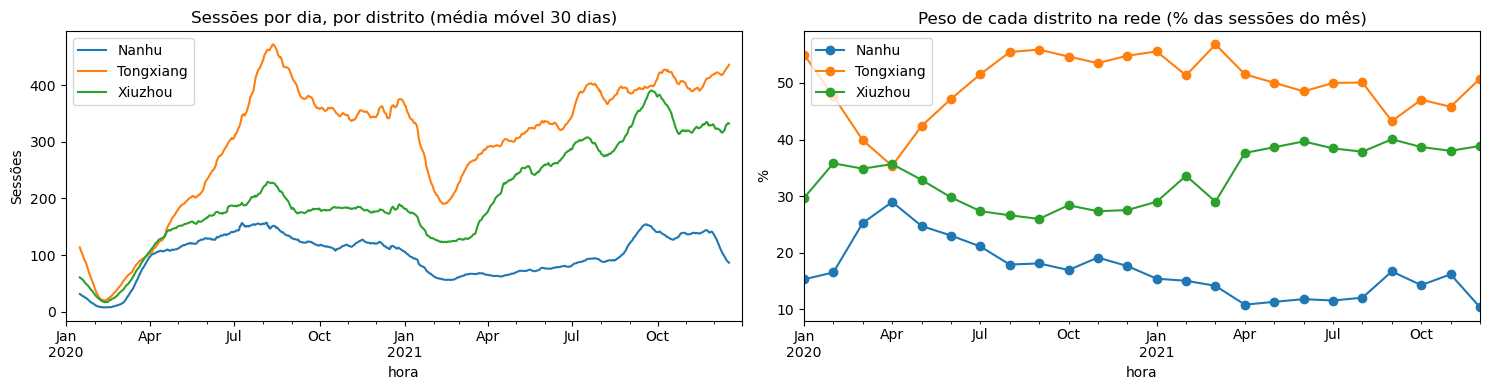

,Nanhu,Tongxiang,Xiuzhou
hora,,,
2020Q1,20.0,47.4,32.6
2020Q2,25.1,42.5,32.4
2020Q3,19.0,54.3,26.7
2020Q4,17.9,54.3,27.8
2021Q1,14.9,54.9,30.2
2021Q2,11.4,49.9,38.7
2021Q3,13.6,47.6,38.8
2021Q4,13.6,47.9,38.5


In [23]:
# 2) Tendência de cada distrito e evolução do peso na rede
diario_d = series[nomes_distritos].resample('D').sum()
mm30_d = diario_d.rolling(30, center=True).mean()

quota = series[nomes_distritos].resample('MS').sum()
quota = quota.div(quota.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

mm30_d.plot(ax=axes[0])
axes[0].set_title('Sessões por dia, por distrito (média móvel 30 dias)')
axes[0].set_ylabel('Sessões')

quota.plot(ax=axes[1], marker='o')
axes[1].set_title('Peso de cada distrito na rede (% das sessões do mês)')
axes[1].set_ylabel('%')

plt.tight_layout()
plt.show()

# Peso por trimestre (tabela resumo)
quota_trim = series[nomes_distritos].resample('QS').sum()
quota_trim = (quota_trim.div(quota_trim.sum(axis=1), axis=0) * 100).round(1)
quota_trim.index = quota_trim.index.to_period('Q').astype(str)
quota_trim

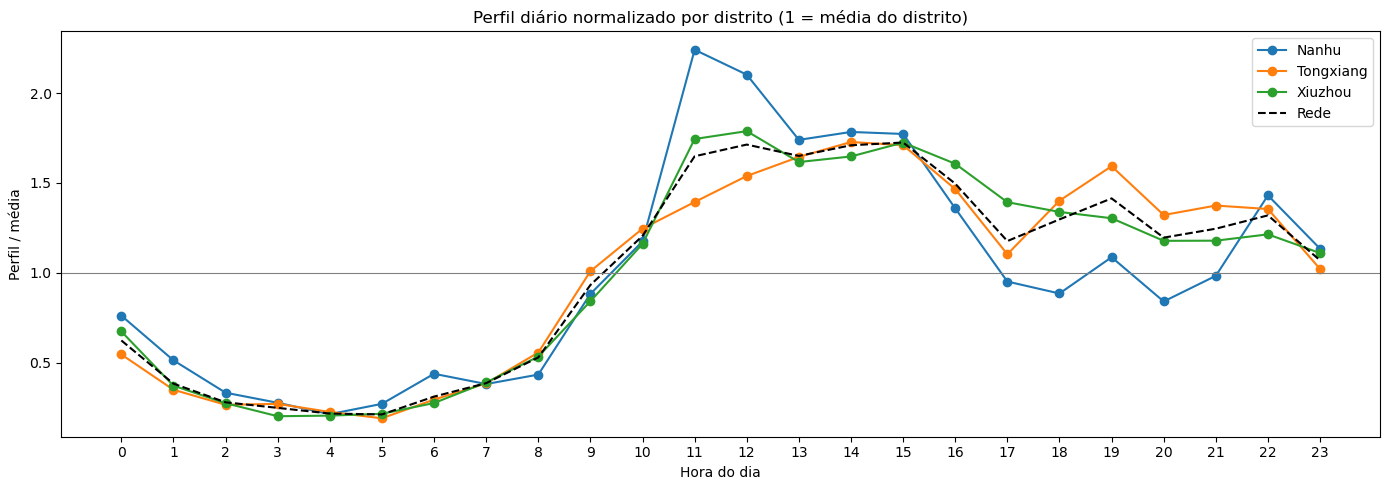

Correlação entre os perfis diários dos distritos:
           Nanhu  Tongxiang  Xiuzhou
Nanhu      1.000      0.864    0.928
Tongxiang  0.864      1.000    0.964
Xiuzhou    0.928      0.964    1.000


In [24]:
# 3) Forma do padrão diário: perfis normalizados (perfil / média)
perfis = d.groupby(d.index.hour)[nomes_distritos + ['Rede']].mean()
perfis_norm = perfis / perfis.mean()

fig, ax = plt.subplots(figsize=(14, 5))
for c in nomes_distritos:
    ax.plot(perfis_norm.index, perfis_norm[c], marker='o', label=c)
ax.plot(perfis_norm.index, perfis_norm['Rede'], color='black', linestyle='--', label='Rede')
ax.axhline(1, color='gray', linewidth=0.8)
ax.set_title('Perfil diário normalizado por distrito (1 = média do distrito)')
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Perfil / média')
ax.set_xticks(range(0, 24))
ax.legend()
plt.tight_layout()
plt.show()

# Semelhança entre as formas: correlação entre os perfis normalizados
print('Correlação entre os perfis diários dos distritos:')
print(perfis_norm[nomes_distritos].corr().round(3))

In [25]:
# 4) Autocorrelação em lags-chave para cada série (escala log)
linhas = {}
for c in ['Rede'] + nomes_distritos:
    v = acf(np.log1p(d[c]), nlags=168)
    linhas[c] = {'lag 1': v[1], 'lag 24': v[24], 'lag 144': v[144], 'lag 168': v[168]}

print('ACF de log(1 + y) por série:')
pd.DataFrame(linhas).T.round(3)

ACF de log(1 + y) por série:


,lag 1,lag 24,lag 144,lag 168
Rede,0.830,0.868,0.842,0.844
Nanhu,0.610,0.659,0.625,0.622
Tongxiang,0.774,0.813,0.786,0.786
Xiuzhou,0.703,0.716,0.693,0.697


**Hipóteses e validação:**

- **H15 - Os distritos de menor volume são mais irregulares: Confirmada.**

  | Série | % da rede | CV | % horas a zero |
  |---|---|---|---|
  | Tongxiang | 50,2 | 0,70 | 1,9 |
  | Xiuzhou | 33,7 | 0,83 | 6,0 |
  | Nanhu | 16,1 | 0,95 | 15,1 |

  A ordem por volume coincide com a ordem por CV e por % de horas a zero. (A % de zeros de Nanhu é inferior à da secção 1.3 porque aqui o período atípico jan–mar 2020 está excluído.)

- **H16 - Os 3 distritos seguem a mesma tendência: Rejeitada.**
  O peso de cada distrito na rede varia ao longo do tempo:
  - **Nanhu** perde peso (25,1% no 2.º trimestre de 2020 → 13,6% no 4.º trimestre de 2021);
  - **Xiuzhou** ganha peso (~27% no 2.º semestre de 2020 → ~38,5% a partir de abril de 2021);
  - **Tongxiang** tem um pico no verão de 2020 e estabiliza em ~48% em 2021.

  Cada distrito tem a sua própria tendência. **Implicação:** não é adequado prever a rede e repartir a previsão por percentagens fixas. Cada distrito deve ter a sua própria previsão, e os dados mais recentes são mais representativos do comportamento atual.

- **H17 - Os 3 distritos têm a mesma forma de padrão diário: Parcialmente confirmada.**
  A forma geral é semelhante (correlação entre perfis de 0,86 a 0,96): madrugada baixa, subida entre as 8h e as 11h e patamar durante o dia. ***m* = 24 é válido para todos.**
  Diferenças nos detalhes:
  - **Nanhu:** pico acentuado às 11–12h (~2,2 vezes a sua média), quebras às 17–18h e às 20h e pico às 22h;
  - **Tongxiang:** subida mais gradual de manhã e pico noturno mais forte às 19h;
  - **Xiuzhou:** perfil mais próximo do da rede.

- **H18 - A sazonalidade de 24h é dominante em todos os distritos: Confirmada.**

  | Série | lag 1 | lag 24 | lag 144 | lag 168 |
  |---|---|---|---|---|
  | Rede | 0,830 | 0,868 | 0,842 | 0,844 |
  | Tongxiang | 0,774 | 0,813 | 0,786 | 0,786 |
  | Xiuzhou | 0,703 | 0,716 | 0,693 | 0,697 |
  | Nanhu | 0,610 | 0,659 | 0,625 | 0,622 |

  Em todas as séries o lag 24 é o mais elevado, e o lag 168 é praticamente igual ao lag 144.
  A autocorrelação diminui com o volume: a série de **Nanhu é a mais ruidosa** e, à partida, a mais difícil de prever; a **rede é a mais previsível**, porque a agregação compensa parte do ruído dos distritos.

**Implicação para a avaliação:** as séries têm escalas muito diferentes (Nanhu ~4,5 sessões/hora; rede ~28), por isso o MAE e o RMSE não são comparáveis entre séries. O **MASE**, por ser relativo ao seasonal naïve de cada série, permite essa comparação.

### 2.6 Decisões para a formulação e avaliação (essa célula pode ser alterada)

Esta secção resume as conclusões das secções 1 e 2 que servem de base à formulação operacional (secção 3) e ao protocolo de avaliação (secção 4).

**Dados disponíveis no notebook**

| Elemento | Valor |
|---|---|
| Variável | `series` (DataFrame com as colunas `Rede`, `Nanhu`, `Tongxiang`, `Xiuzhou`) |
| Alvo | Nº de sessões de carregamento que **começam** em cada hora |
| Frequência | Horária |
| Período | 01/01/2020 00:00 a 31/12/2021 23:00 (17 544 horas) |
| Horas sem sessões | Mantidas como **procura zero real** (sem imputação) |

**Decisões e recomendações**

| Tema | Conclusão | Onde foi validado | Recomendação para a Parte B |
|---|---|---|---|
| Período atípico | jan–mar 2020 tem procura anormalmente baixa (Ano Novo Chinês + COVID-19) | 1.2 (H2), 1.3 (H4) | Considerar iniciar o treino em **01/04/2020** |
| Tendência | Crescente a longo prazo; a série não é estacionária no sentido estrito | 2.1 (H5), 2.4 (H14) | Dar mais importância aos dados recentes |
| Tipo de sazonalidade | **Multiplicativa** (amplitude cresce com o nível) | 2.3 (H10) | Considerar a transformação log(1 + y) nos modelos |
| Período sazonal *m* | ***m* = 24** dominante; semanal (*m* = 168) fraca | 2.2 (H8, H9), 2.3 (H11), 2.4 (H12, H13) | Usar ***m* = 24 no MASE**; comparar os seasonal naïve com *m* = 24 e *m* = 168 |
| Distritos | Tendências diferentes; formas do dia semelhantes mas não iguais | 2.5 (H16, H17) | Fazer **uma previsão por série** (não repartir a previsão da rede por percentagens fixas) |
| Dificuldade por série | Nanhu é a série mais ruidosa e a rede a mais previsível | 2.5 (H15, H18) | Comparar séries com o **MASE** (o MAE e o RMSE dependem da escala) |
| Datas especiais | Picos e quebras em feriados (Ano Novo Chinês, Dia Nacional, véspera de Ano Novo) | 1.2 (H2), 2.1 (H7) | Considerar variáveis de calendário de feriados |

**Lags candidatos a preditores (PACF, secção 2.4)**

| Lag | Significado | Relação direta | Disponível numa previsão day-ahead? |
|---|---|---|---|
| 1 | hora anterior | Muito forte (0,83) | Apenas para o horizonte h = 1 |
| 24 | mesma hora, dia anterior | Forte (~0,29) | Sim, para todos os horizontes (1 a 24h) |
| 48 | mesma hora, 2 dias antes | Moderada (~0,15) | Sim |
| 72 | mesma hora, 3 dias antes | Fraca (~0,13) | Sim |

**Variáveis de calendário candidatas**

| Variável | Efeito observado | Conhecida no futuro? |
|---|---|---|
| Hora do dia | Muito forte (secção 2.2) | Sim |
| Dia da semana | Fraco (secção 2.2) | Sim |
| Feriados / vésperas | Picos e quebras pontuais (secção 2.1) | Sim |

**Questões em aberto para a Parte B**
- As variáveis meteorológicas (temperatura, humidade, precipitação) **não foram analisadas** nesta parte. São valores **observados**, e o seu uso deve ser avaliado tendo em conta o risco de *leakage* (secção 3.3).
- A definição da hora de emissão da previsão, da estratégia multi-step e dos períodos de treino, validação e teste fica para as secções 3 e 4.